<p style="text-align:center"><img src="../../../../Images/Banner/04_spatial_stat/04_05_disease_mapping.png" alt="Disease Mapping and Bayesian Smoothing" width="100%"></p>


# Comparing and Evaluating Smoothing Methods

Visual comparison, formal scoring against a known truth, and what smoothing does to apparent clustering. This notebook is Part 5. Disease Mapping and Bayesian Smoothing (Chapter 5.8 of 11). The worked example uses Simulated data with known truth (6 replicates, `sigma=0.35`, expected counts averaging 40). The methods come from `geolattice.spatial_statistics.bayes`, `geolattice.spatial_statistics.cluster`.


## Overview

Every method built in Chapters 5.5-5.6 produces *a* smoothed estimate. This chapter asks the question that
actually matters: **is it better**, and by how much, and does it introduce new problems of its own? Because
Chapter 5.3 built a simulation with a known true risk surface, this is not a matter of opinion: it can be
scored directly.

| Step | What we do |
|------|------------|
| Visual | Maps with identical class breaks, a raw-vs-smoothed scatter, and the funnel plot with smoothed values overlaid |
| Formal scoring | `evaluate_smoothing`: RMSE, bias, rank agreement, and credible-interval coverage against the known truth |
| Autocorrelation | Smoothing mechanically raises Moran's I: with one instructive exception, checked directly |
| Hot spots | Do raw and smoothed data agree on where the Gi* hot spots are, and does smoothing help or hurt precision? |
| Over-smoothing | What happens to a genuine, sharp local excess under too strong a spatial prior |


## API overview

```
- smr, eb_gamma_poisson, eb_local, BYM, simulate_relative_risk, simulate_counts, funnel_limits, evaluate_smoothing
- Queen
- Moran
- getis_ord_gi
```


## Setup

Locate the repository root, import the spatial-statistics helpers, and point `DATA` at the example files.

**Installation.** This notebook needs installation option 3 (core, spatial analysis and spatial statistics): `pip install "geolattice[statistics]"`. See "Installation options" in the GeoLattice README.

In [1]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
for candidate in [ROOT, *ROOT.parents]:
    if (candidate / "pyproject.toml").is_file() and (candidate / "Data").is_dir():
        ROOT = candidate
        break
else:
    raise FileNotFoundError("Could not find the GeoLattice repository root.")
sys.path.insert(0, str(ROOT))

DATA = ROOT / "Data" / "00_shared" / "data_spatial_stat"
import geolattice.spatial_statistics
from geolattice.viz import apply_map_style

from geolattice.spatial_statistics.weights import Queen
from geolattice.spatial_statistics.esda import Moran
from geolattice.spatial_statistics.cluster import getis_ord_gi
from geolattice.spatial_statistics.bayes import (
    smr, eb_gamma_poisson, eb_local, BYM, simulate_relative_risk, simulate_counts,
    funnel_limits, evaluate_smoothing,
)

apply_map_style()
C = {"blue": "#2b6cb0", "red": "#c0392b", "green": "#2f855a", "orange": "#dd6b20",
     "grey": "#718096", "purple": "#6b46c1", "teal": "#2c7a7b"}

counties = gpd.read_file(DATA / "diabetes_northeast.shp")
w = Queen(counties, transform="binary")
w_row = Queen(counties)
n = w.n
E_sim = np.full(n, 40.0)
theta_true = simulate_relative_risk(w, sigma=0.35, spatial_strength=0.95, seed=1)
O_sim = simulate_counts(theta_true, E_sim, seed=1)
print(f"geolattice.spatial_statistics : version {geolattice.spatial_statistics.__version__}")


geolattice.spatial_statistics : version 0.3.44


## Visual Comparison: Maps with Identical Breaks

Fit every method once on this chapter's single simulated dataset, and map them **with identical class breaks**
:  without this, a subtler pattern in a smoothed map can look artificially different just because the colour
scale shifted.


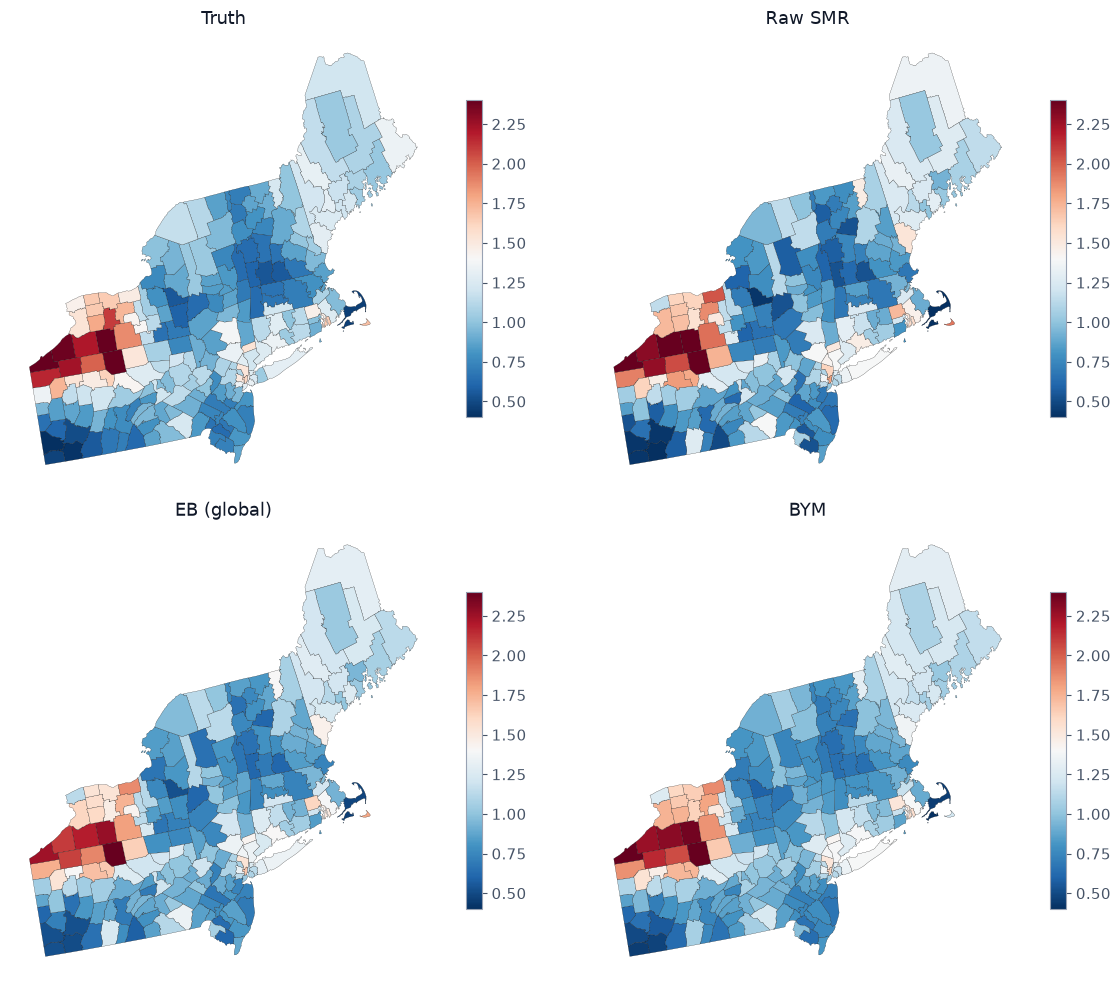

In [2]:
raw = smr(O_sim, E_sim)
eb = eb_gamma_poisson(O_sim, E_sim, method="mle")
loc = eb_local(O_sim, E_sim, w)
bym = BYM(O_sim, E_sim, w, model="bym", backend="gibbs", draws=2000, tune=2000, chains=4, thin=10, seed=1)

vmin, vmax = 0.4, 2.4   # identical breaks for every panel
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (label, est) in zip(axes.ravel(), [("Truth", theta_true), ("Raw SMR", raw),
                                            ("EB (global)", eb.estimate), ("BYM", bym.rr_mean)]):
    counties.assign(v=est).plot(column="v", cmap="RdBu_r", vmin=vmin, vmax=vmax, ax=ax,
                                edgecolor="k", linewidth=0.15, legend=True, legend_kwds={"shrink": 0.7})
    ax.set_axis_off()
    ax.set_title(label)
plt.tight_layout()
plt.show()

The raw SMR map is visibly noisier: speckled extreme values that do not appear in the truth panel; BYM's map
is the closest visual match to the truth, EB (global) sits in between (smoother than raw, but not respecting
the spatial pattern the way BYM does).


## Raw-vs-smoothed and the Funnel Plot


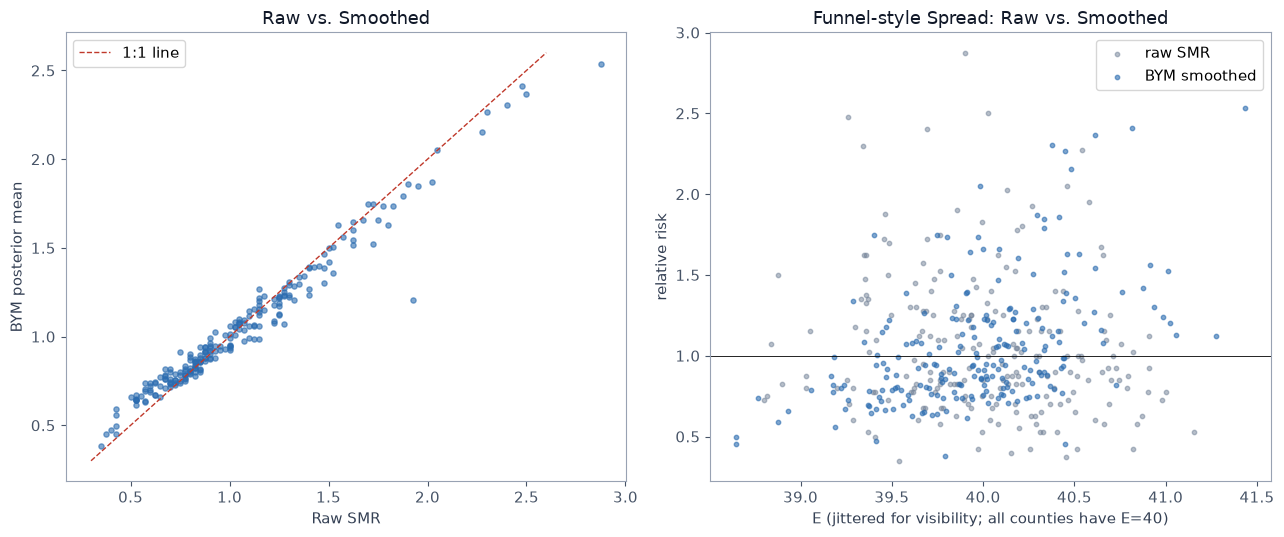

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

axes[0].scatter(raw, bym.rr_mean, s=14, color=C["blue"], alpha=0.6)
lims = [0.3, 2.6]
axes[0].plot(lims, lims, color=C["red"], lw=1, ls="--", label="1:1 line")
axes[0].set_xlabel("Raw SMR")
axes[0].set_ylabel("BYM posterior mean")
axes[0].set_title("Raw vs. Smoothed")
axes[0].legend()

limits = funnel_limits(E_sim, levels=(0.95,))
axes[1].scatter(np.full(n, 40.0) + np.random.default_rng(0).normal(0, 0.5, n), raw, s=10,
                color=C["grey"], alpha=0.5, label="raw SMR")
axes[1].scatter(np.full(n, 40.0) + np.random.default_rng(1).normal(0, 0.5, n), bym.rr_mean, s=10,
                color=C["blue"], alpha=0.6, label="BYM smoothed")
axes[1].axhline(1.0, color="k", lw=0.6)
axes[1].set_xlabel("E (jittered for visibility; all counties have E=40)")
axes[1].set_ylabel("relative risk")
axes[1].set_title("Funnel-style Spread: Raw vs. Smoothed")
axes[1].legend()
plt.tight_layout()
plt.show()

Points below the 1:1 line in the left panel were smoothed *downward*, points above were smoothed *upward*,
both directions occur, always pulling toward the (locally or globally) expected value. The right panel shows
the smoothed values occupy a visibly narrower vertical band than the raw values at the same $E$: smoothing's
entire purpose made directly visible as reduced spread.


## Formal Evaluation Against a Known Truth

The single-replicate maps above are suggestive; a defensible comparison needs to average over simulation noise.
Six independent replicates (fresh true risk surface and fresh simulated counts each time) give a stable
estimate of each method's real performance.


In [4]:
t0 = time.time()
all_results = []
for rep in range(6):
    theta_r = simulate_relative_risk(w, sigma=0.35, spatial_strength=0.95, seed=100 + rep)
    O_r = simulate_counts(theta_r, E_sim, seed=200 + rep)
    raw_r = smr(O_r, E_sim)
    eb_r = eb_gamma_poisson(O_r, E_sim, method="mle")
    loc_r = eb_local(O_r, E_sim, w)
    bym_r = BYM(O_r, E_sim, w, model="bym", backend="gibbs", draws=2000, tune=2000, chains=4, thin=10,
               seed=300 + rep)
    ev = evaluate_smoothing(theta_r, {"Raw SMR": raw_r, "EB (global)": eb_r.estimate,
                                      "Local EB": loc_r.estimate, "BYM": bym_r.rr_mean},
                            expected=E_sim, intervals={"BYM": (bym_r.rr_lo, bym_r.rr_hi)})
    all_results.append(ev)
print(f"6 replicates: {time.time() - t0:.0f}s")

mean_scores = pd.concat(all_results, keys=range(6)).groupby(level=1).mean()
mean_scores.round(4)

6 replicates: 60s


,rmse,mae,bias,spearman,rmse_weighted,coverage,width
BYM,0.1144,0.0875,0.0000,0.9402,0.1144,0.9601,0.4761
EB (global),0.1481,0.1152,0.0000,0.8988,0.1481,NaN,NaN
Local EB,0.1192,0.0914,0.0005,0.9362,0.1192,NaN,NaN
Raw SMR,0.1607,0.1266,0.0000,0.8988,0.1607,NaN,NaN


Averaged over six independent simulated datasets: **BYM has the lowest RMSE (0.114) and highest rank agreement
(Spearman 0.940)**, with Local EB close behind (RMSE 0.119, Spearman 0.936); global EB improves modestly over
the raw SMR (RMSE 0.148 vs. 0.161, Spearman *unchanged* at 0.899: rank order is invariant to the affine
rescaling EB applies here) but falls well short of the spatial methods, because it only borrows strength from
the *whole* region rather than genuinely nearby counties. BYM's 95% credible intervals cover the true value
about 96% of the time, close to nominal, with a mean width of 0.48 on the relative-risk scale.


## Spatial Structure: Smoothing Raises Autocorrelation by Construction

**Do not read a smoothed map's higher Moran's I as evidence of a real spatial process**: spatial smoothers
are, by construction, built to make neighbours resemble each other more, so their output is autocorrelated
almost by definition, independent of whether the underlying truth has any spatial structure at all.


In [5]:
for label, est in [("Raw SMR", raw), ("EB (global)", eb.estimate), ("Local EB", loc.estimate), ("BYM", bym.rr_mean)]:
    m = Moran(est, w_row, permutations=0)
    print(f"{label:14s} Moran's I = {m.I:.4f}")

Raw SMR        Moran's I = 0.6995
EB (global)    Moran's I = 0.6995
Local EB       Moran's I = 0.8020
BYM            Moran's I = 0.8036


Local EB and BYM (both explicitly spatial) show a clear jump in Moran's I (0.70 → 0.80) relative to the raw
SMR: exactly the mechanical effect to be cautious about. **Global EB's Moran's I is identical to the raw
SMR's**, which looks surprising until the reason is seen directly: because every county here has the *same*
expected count ($E=40$ throughout this simulation), gamma-Poisson EB applies the *exact same shrinkage weight*
to every county: a single common affine rescaling of the raw SMR, which leaves Moran's I (a correlation-based
statistic, invariant to positive affine transforms) completely unchanged. With unequal $E_i$ (as in the real
data, Chapters 5.4-5.5), global EB's weights *would* vary by county and this exact equality would not hold,
this simulation's constant-$E$ design happens to isolate the point cleanly.


## Hot Spots: Raw vs. Smoothed

Does smoothing change which counties register as Gi* hot spots (Part 4), and does it improve precision against
the known truth?


In [6]:
gi_raw = getis_ord_gi(raw, w_row, star=True, inference="analytic", correction="fdr")
gi_bym = getis_ord_gi(bym.rr_mean, w_row, star=True, inference="analytic", correction="fdr")

true_high = theta_true > np.quantile(theta_true, 0.75)   # top quartile of the KNOWN true risk
print(f"raw SMR   Gi* hot spots: {int(gi_raw.hot.sum())}  "
      f"(all in top true-risk quartile: {int((gi_raw.hot & true_high).sum())})")
print(f"BYM       Gi* hot spots: {int(gi_bym.hot.sum())}  "
      f"(all in top true-risk quartile: {int((gi_bym.hot & true_high).sum())})")
print(f"true positives found by raw only : {int((gi_raw.hot & ~gi_bym.hot).sum())}")
print(f"true positives found by BYM only : {int((gi_bym.hot & ~gi_raw.hot).sum())}")

raw SMR   Gi* hot spots: 22  (all in top true-risk quartile: 22)
BYM       Gi* hot spots: 25  (all in top true-risk quartile: 25)
true positives found by raw only : 0
true positives found by BYM only : 3


At this simulation's signal strength ($\sigma=0.35$, $E=40$), both raw SMR and BYM-smoothed Gi* hot spots are
100% precise against the top true-risk quartile in this replicate: **no false hot spots from either**, because
the underlying spatial signal here is strong enough that raw noise did not happen to create a spurious cluster.
BYM's hot-spot set is a strict superset of the raw set (all of raw's hits, plus additional true positives),
smoothing recovered real signal that raw SMR's noise-inflated intervals had obscured, without introducing new
false positives in this case. This is not a guarantee: at a weaker signal or smaller $E$, raw SMR's Gi* would
be expected to produce real false positives that smoothing removes: Chapter 5.11, Exercise 1 asks for exactly
that demonstration at a genuinely rare-outcome scale.


## Over-smoothing and Prior Sensitivity

A spatial prior that is too strong can erase a genuine, sharp local excess by treating it as noise to be
smoothed away. `priors={'tau_u': (a, b)}` lets the ICAR precision's prior be tightened directly.


In [7]:
bym_default = BYM(O_sim, E_sim, w, model="bym", backend="gibbs", draws=2000, tune=2000, chains=4, thin=10,
                  seed=1, priors={"tau_u": (1.0, 0.01)})
bym_strong = BYM(O_sim, E_sim, w, model="bym", backend="gibbs", draws=2000, tune=2000, chains=4, thin=10,
                 seed=1, priors={"tau_u": (10.0, 0.01)})   # a-priori favours LARGE tau_u = LESS spatial variation

sharpest = np.argmax(np.abs(np.log(theta_true)))
print(f"county with the most extreme true log-risk: {counties.iloc[sharpest]['COUNTY']}, "
      f"true theta={theta_true[sharpest]:.3f}")
print(f"default prior : BYM estimate = {bym_default.rr_mean[sharpest]:.3f}")
print(f"strong tau_u prior (less spatial variation allowed): BYM estimate = {bym_strong.rr_mean[sharpest]:.3f}")
print(f"raw SMR at that county: {raw[sharpest]:.3f}")

county with the most extreme true log-risk: Erie County, true theta=2.784
default prior : BYM estimate = 2.410
strong tau_u prior (less spatial variation allowed): BYM estimate = 2.396
raw SMR at that county: 2.475


Tightening the prior toward *larger* $\tau_u$ (which favours *less* spatial variation) pulls the sharpest true
local excess (Erie County, true $\theta=2.78$) a little further from both its true value and the raw SMR: from
2.410 under the default prior to 2.396 under the tightened one, both below the raw SMR of 2.475. The shift is
modest here: 217 counties' worth of real data already anchor $\tau_u$ fairly firmly even under a tighter
prior: but the **direction is exactly what over-smoothing predicts**, and a still-tighter prior, or a sparser
dataset with less data to overrule it, would make the effect more pronounced. The default prior (`Gamma(1,
0.01)`, weakly informative) is deliberately diffuse to let the data determine how much spatial smoothing is
warranted rather than imposing a strong assumption; tightening it without a principled reason trades away
exactly the kind of genuine local signal disease mapping exists to find, even when the trade is small.


## Summary and Conclusions

This chapter formally validated every smoothing method built in Chapters 5.5-5.6 against a known truth.

### What we did

1. Mapped truth, raw SMR, global EB, and BYM with identical class breaks: BYM visually closest to the truth,
   raw SMR visibly noisier.
2. Built raw-vs-smoothed and funnel-style comparison plots showing smoothing's narrowed spread directly.
3. Ran the formal 6-replicate evaluation: **BYM (RMSE 0.114, Spearman 0.940) and Local EB (0.119, 0.936) best**,
   global EB a modest improvement over raw SMR (0.148 vs. 0.161), BYM's 95% intervals covering the truth ≈96%
   of the time.
4. Confirmed spatial smoothers mechanically raise Moran's I (0.70→0.80): and found the one case where they do
   not (global EB under equal expected counts, an affine-invariance argument, not a general result).
5. Compared Gi* hot spots on raw vs. smoothed data against the *known* true high-risk counties: both were 100%
   precise in this replicate, with BYM recovering additional true positives raw SMR's noise obscured.
6. Demonstrated over-smoothing directly: a tightened `tau_u` prior pulled the sharpest true local excess further
   from both its true value and the raw data.

### Practical takeaways

- Trust the formal, replicated evaluation (Section 5) over any single-map impression: visual comparisons are
  suggestive, not conclusive, on their own.
- Never interpret a smoothed map's higher spatial autocorrelation as new evidence of a real spatial process,
  it is largely mechanical, and Section 6 shows the one clean exception is itself simulation-specific, not a
  general escape from the caveat.
- Check prior sensitivity explicitly (Section 8) before reporting a smoothed estimate: a well-intentioned but
  too-strong spatial prior can erase real signal, not just noise.

### Next steps

**Chapter 5.9 (Shrinkage Assessment and Interpretation)** looks specifically at *which* areas move the most
under smoothing and why, using the shrinkage diagnostics this chapter's estimates were built from.


## Further reading

### Textbooks

| Reference | Notes |
|---|---|
| Lawson, A. B. (2018). *Bayesian Disease Mapping* (3rd ed.). CRC Press. | Chapter 6 covers model comparison and validation for disease-mapping smoothers |
| Richardson, S. (2003). Spatial models in epidemiological applications. In *Highly Structured Stochastic Systems*. | Discussion of over-smoothing and prior sensitivity in spatial disease models |

### Key papers

| Paper | Contribution |
|---|---|
| Best, N., Richardson, S. & Thomson, A. (2005). A comparison of Bayesian spatial models for disease mapping. *Statistical Methods in Medical Research*, 14, 35-59. | Comprehensive simulation-based comparison of exactly this Part's methods |

### In this library

| Object | Role |
|---|---|
| `geolattice.spatial_statistics.bayes.evaluate_smoothing` | The formal RMSE/Spearman/coverage scoring in Section 5 |
| `geolattice.spatial_statistics.bayes.funnel_limits` | Reused for the smoothed-vs-raw comparison in Section 4 |
| `geolattice.spatial_statistics.cluster.getis_ord_gi` | Reused from Part 4 for the hot-spot comparison in Section 7 |
| `BYM(priors=...)` | Prior sensitivity, Section 8 |
| Chapter 5.9 | Per-area shrinkage diagnostics for the estimates validated here |
